In [3]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
sys.path.append(str(Path.cwd().parent / "src"))
from features import FEATURES
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, classification_report, confusion_matrix

PROJ = Path.home() / "Documents/v2x-ids"
df = pd.read_parquet(PROJ / "data/processed/features_run79200.parquet")
X, groups = df[FEATURES], df["sender"]

FAMILY = {"Genuine": "Genuine",
    "ConstPos": "Position", "ConstPosOffset": "Position", "RandomPos": "Position",
    "RandomPosOffset": "Position", "EventualStop": "Position",
    "ConstSpeed": "Speed", "ConstSpeedOffset": "Speed", "RandomSpeed": "Speed", "RandomSpeedOffset": "Speed",
    "Disruptive": "Replay/Delay", "DataReplay": "Replay/Delay", "DelayedMessages": "Replay/Delay",
    "DoS": "DoS", "DoSRandom": "DoS", "DoSDisruptive": "DoS",
    "GridSybil": "Sybil", "DataReplaySybil": "Sybil", "DoSRandomSybil": "Sybil", "DoSDisruptiveSybil": "Sybil"}
df["family"] = df["attack_name"].map(FAMILY)

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
tr, te = next(sgkf.split(X, df["label"], groups))

In [4]:
rf20 = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42, class_weight="balanced")
rf20.fit(X.iloc[tr], df["attack_name"].iloc[tr])
p20, yt20 = rf20.predict(X.iloc[te]), df["attack_name"].iloc[te]
print(f"macro-F1: {f1_score(yt20, p20, average='macro'):.3f} | weighted-F1: {f1_score(yt20, p20, average='weighted'):.3f}")

rep20 = pd.DataFrame(classification_report(yt20, p20, output_dict=True, zero_division=0)).T
rep20 = rep20.loc[sorted(set(yt20)), ["precision", "recall", "f1-score", "support"]].sort_values("f1-score")
rep20.round(2)

macro-F1: 0.593 | weighted-F1: 0.810


,precision,recall,f1-score,support
ConstPosOffset,0.01,0.00,0.00,247.0
ConstSpeed,0.52,0.07,0.12,236.0
DataReplaySybil,0.13,0.13,0.13,652.0
ConstSpeedOffset,0.32,0.10,0.15,431.0
DataReplay,0.23,0.20,0.21,348.0
Disruptive,0.31,0.53,0.39,368.0
DoSDisruptiveSybil,0.40,0.61,0.48,916.0
DoSDisruptive,0.92,0.45,0.61,951.0
EventualStop,0.57,0.66,0.61,277.0
RandomSpeedOffset,0.50,0.86,0.64,468.0


In [5]:
rf6 = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42, class_weight="balanced")
rf6.fit(X.iloc[tr], df["family"].iloc[tr])
p6, yt6 = rf6.predict(X.iloc[te]), df["family"].iloc[te]
print(f"macro-F1: {f1_score(yt6, p6, average='macro'):.3f} | weighted-F1: {f1_score(yt6, p6, average='weighted'):.3f}")

rep6 = pd.DataFrame(classification_report(yt6, p6, output_dict=True, zero_division=0)).T
rep6.loc[sorted(set(yt6)), ["precision", "recall", "f1-score", "support"]].sort_values("f1-score").round(2)

macro-F1: 0.834 | weighted-F1: 0.879


,precision,recall,f1-score,support
Replay/Delay,0.57,0.68,0.62,1145.0
Sybil,0.81,0.66,0.73,6012.0
Position,0.83,0.76,0.79,1878.0
Genuine,0.90,0.96,0.93,18494.0
Speed,0.96,0.96,0.96,1489.0
DoS,0.98,0.97,0.98,3501.0


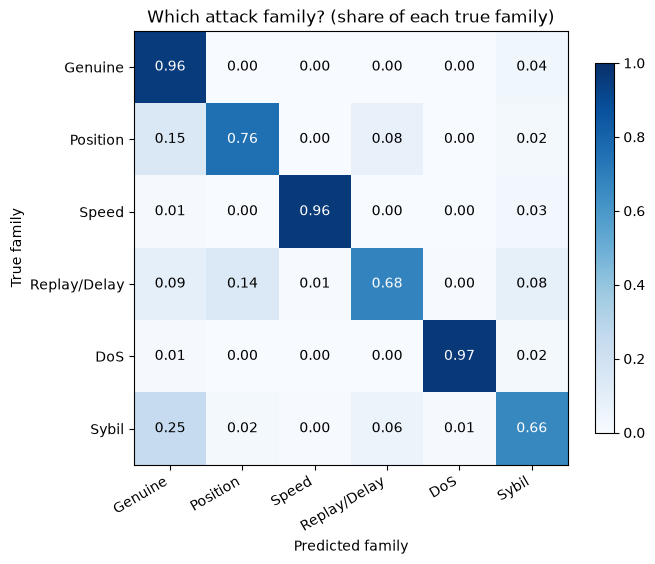

In [6]:
labels = ["Genuine", "Position", "Speed", "Replay/Delay", "DoS", "Sybil"]
cm = confusion_matrix(yt6, p6, labels=labels, normalize="true")

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(6), labels, rotation=30, ha="right")
ax.set_yticks(range(6), labels)
for i in range(6):
    for j in range(6):
        ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center",
                color="white" if cm[i, j] > 0.5 else "black")
ax.set_xlabel("Predicted family"); ax.set_ylabel("True family")
ax.set_title("Which attack family? (share of each true family)")
fig.colorbar(im, ax=ax, shrink=0.8)
fig.savefig(PROJ / "results/figures/fig_family_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
rep20.round(3).to_csv(PROJ / "results/task12_per_attack_type.csv")
rep6.round(3).to_csv(PROJ / "results/task12_per_family.csv")
print("Saved!")

Saved!
